# Food Safety Analysis - San Francisco Restaurants

**Objective:** Analyze restaurant health inspection outcomes, violation severity, neighborhood compliance disparities, and reinspection turnaround patterns across San Francisco, train a leak-free non-pass risk classifier (`RandomForestClassifier`), and visualize spatial compliance risk using the official **DataSF Health Inspections (2023-Present)** dataset (`tvy3-wexg`).

**Dataset:** `dataset/sf_health_inspections.csv` (`23,243` inspection records across `8,802` unique permits).

## 1. Environment Setup & Data Loading

Configure visualization defaults, load the unified inspection CSV, and inspect the schema and missing-value profile.

In [1]:
# pip install numpy pandas matplotlib seaborn scikit-learn folium joblib

import os

import folium
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import IFrame, display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

os.makedirs('dataset', exist_ok=True)
os.makedirs('model', exist_ok=True)
os.makedirs('visualizations', exist_ok=True)

pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid', context='notebook')

DATA_PATH = 'dataset/sf_health_inspections.csv'
raw_df = pd.read_csv(DATA_PATH, low_memory=False)

print(f"Dataset shape: {raw_df.shape[0]:,} rows x {raw_df.shape[1]} columns")
print(f"Unique permits: {raw_df['permit_number'].nunique():,} | Unique businesses (DBA): {raw_df['dba'].nunique():,}")
raw_df.head(3)

Dataset shape: 23,243 rows x 26 columns
Unique permits: 8,802 | Unique businesses (DBA): 7,639


,inspection_date,inspector,district,subdistrict,subsector,permit_number,dba,permit_type,street_address,street_address_clean,inspection_type,inspection_frequency_type,total_time,facility_rating_status,census,suspension_notes,inspection_notes,violation_count,violation_codes,latitude,longitude,point,analysis_neighborhood,supervisor_district,data_as_of,data_loaded_at
0,2025/06/24 12:00:00 AM,Katherine Tuazon,3,302,218,06744403,ANDYTOWN COFFEE ROASTERS,"H24 - RESTAURANT UNDER 1,000 SQFT",2815 DIAMOND ST,2815 DIAMOND ST,NaN,2,100.0,Pass,NaN,NaN,NaN,NaN,NaN,37.733985,-122.433638,POINT (-122.4336375 37.733985),Glen Park,8.0,2025/06/27 02:00:10 AM,2026/11/21 02:36:29 AM
1,2025/06/26 12:00:00 AM,Danny Nguyen,5,502,402,06744267,SAGARMATHA KITCHEN,"H25 - RESTAURANT 1,000 - 2,000 SQFT",4828 GEARY BLVD,4828 GEARY BLVD,NaN,2,75.0,Pass,NaN,NaN,NaN,NaN,NaN,37.781019,-122.471276,POINT (-122.4712755 37.781019),Inner Richmond,1.0,2025/06/27 02:00:10 AM,2026/11/21 02:36:29 AM
2,2025/06/24 12:00:00 AM,Danny Nguyen,1,104,SUMMER,06744276,Aim High - Excelsior,Summer Meals,450 SOMERSET ST,450 SOMERSET ST,NaN,1,20.0,Pass,NaN,NaN,NaN,NaN,NaN,37.725696,-122.407682,POINT (-122.4076815 37.725696),Portola,9.0,2025/06/27 02:00:10 AM,2026/11/21 02:36:29 AM


In [2]:
# Schema and missingness audit
audit = pd.DataFrame({
    'dtype': raw_df.dtypes.astype(str),
    'non_null': raw_df.notna().sum(),
    'missing': raw_df.isna().sum(),
    'missing_pct': (raw_df.isna().mean() * 100).round(2),
    'n_unique': raw_df.nunique(),
})
audit.sort_values('missing_pct', ascending=False)

,dtype,non_null,missing,missing_pct,n_unique
suspension_notes,float64,0,23243,100.00,0
inspection_notes,float64,0,23243,100.00,0
violation_codes,str,12759,10484,45.11,7917
violation_count,float64,12759,10484,45.11,26
inspection_type,str,16673,6570,28.27,14
census,str,17622,5621,24.18,164
facility_rating_status,str,21626,1617,6.96,3
inspection_frequency_type,str,22246,997,4.29,3
analysis_neighborhood,str,23045,198,0.85,41
supervisor_district,float64,23045,198,0.85,11


## 2. Data Cleaning & Anomaly Resolution

Real-world municipal inspection logs contain recording errors and mixed permit scopes. We resolve five concrete issues before analysis:
1. **Timestamp Parsing & Future-Date Outliers:** Parse `inspection_date` and `data_as_of` cleanly; flag and exclude records dated after `data_as_of` (e.g., an erroneous `2031-05-16` entry).
2. **Missing Outcomes & Zero-Violation Imputation:** Missing `violation_count` values correspond to inspections with no recorded violations (`0`), while blank `facility_rating_status` and `inspection_type` values are labeled `'Unspecified'`.
3. **Duration Anomalies (`total_time`):** Negative or extreme inspection durations (e.g., `-1320` minutes) are set to `NaN` rather than corrupting summary statistics.
4. **Geospatial Bounding Box Validation:** Retain San Francisco coordinates (`37.65 <= latitude <= 37.85`, `-122.55 <= longitude <= -122.35`) when mapping, isolating out-of-bounds entries (e.g., `33.76`).
5. **Food & Restaurant Permit Flagging:** Classify restaurant permits (`H24`, `H25`, `H26`, `H25R`, `H26R`) separately from non-food permits such as tobacco retail (`H31`).

In [3]:
df = raw_df.copy()

# 1. Parse timestamps and remove exact duplicates
df['inspection_date'] = pd.to_datetime(df['inspection_date'], format='%Y/%m/%d %I:%M:%S %p', errors='coerce')
df['data_as_of'] = pd.to_datetime(df['data_as_of'], format='%Y/%m/%d %I:%M:%S %p', errors='coerce')
dup_count = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)

max_as_of = df['data_as_of'].max()
future_mask = df['inspection_date'] > max_as_of
print(f"Exact duplicates removed: {dup_count}")
print(f"Anomalous future dates (> {max_as_of.date()}): {future_mask.sum()}")
df = df.loc[~future_mask & df['inspection_date'].notna()].copy()

# 2. Impute violation counts and normalize categorical labels
df['violation_count'] = pd.to_numeric(df['violation_count'], errors='coerce').fillna(0).astype(int)
df['facility_rating_status'] = df['facility_rating_status'].fillna('Unspecified').str.strip()
df['inspection_type'] = df['inspection_type'].fillna('Unspecified').str.strip()
df['analysis_neighborhood'] = df['analysis_neighborhood'].fillna('Unknown').str.strip()

# 3. Clean inspection duration (total_time in minutes)
df['total_time'] = pd.to_numeric(df['total_time'], errors='coerce')
invalid_time = (df['total_time'] <= 0) | (df['total_time'] > 600)
print(f"Invalid total_time values nullified (<=0 or >600 min): {invalid_time.sum()}")
df.loc[invalid_time, 'total_time'] = np.nan

# 4. Derive calendar and compliance flags
df['year_month'] = df['inspection_date'].dt.to_period('M').dt.to_timestamp()
df['is_non_pass'] = df['facility_rating_status'].isin(['Conditional Pass', 'Closure'])
df['is_restaurant'] = df['permit_type'].fillna('').str.contains('RESTAURANT', case=False, regex=False)

# 5. Validate San Francisco geospatial bounds
df['valid_sf_coords'] = (
    df['latitude'].between(37.65, 37.85) & df['longitude'].between(-122.55, -122.35)
)
print(f"Cleaned inspection records: {len(df):,} | Restaurant records: {df['is_restaurant'].sum():,}")
print(f"Inspection window: {df['inspection_date'].min().date()} -> {df['inspection_date'].max().date()}")

Exact duplicates removed: 139
Anomalous future dates (> 2026-11-21): 1
Invalid total_time values nullified (<=0 or >600 min): 409
Cleaned inspection records: 23,103 | Restaurant records: 13,782
Inspection window: 2024-01-02 -> 2026-11-20


## 3. Exploratory Data Analysis (EDA)

### 3.1 Compliance Outcomes & Restaurant Size Breakdown
We compare `Pass`, `Conditional Pass`, and `Closure` rates across all inspections and within restaurant square-footage tiers (`H24 < 1,000 sqft`, `H25 1,000-2,000 sqft`, `H26 > 2,000 sqft`).

facility_rating_status,Closure,Conditional Pass,Pass,Non-Pass Rate (%)
size_label,,,,
"Large (>2,000 sqft)",106,189,3820,7.17
"Medium (1,000-2,000 sqft)",162,220,4914,7.21
"Small (<1,000 sqft)",108,154,3990,6.16


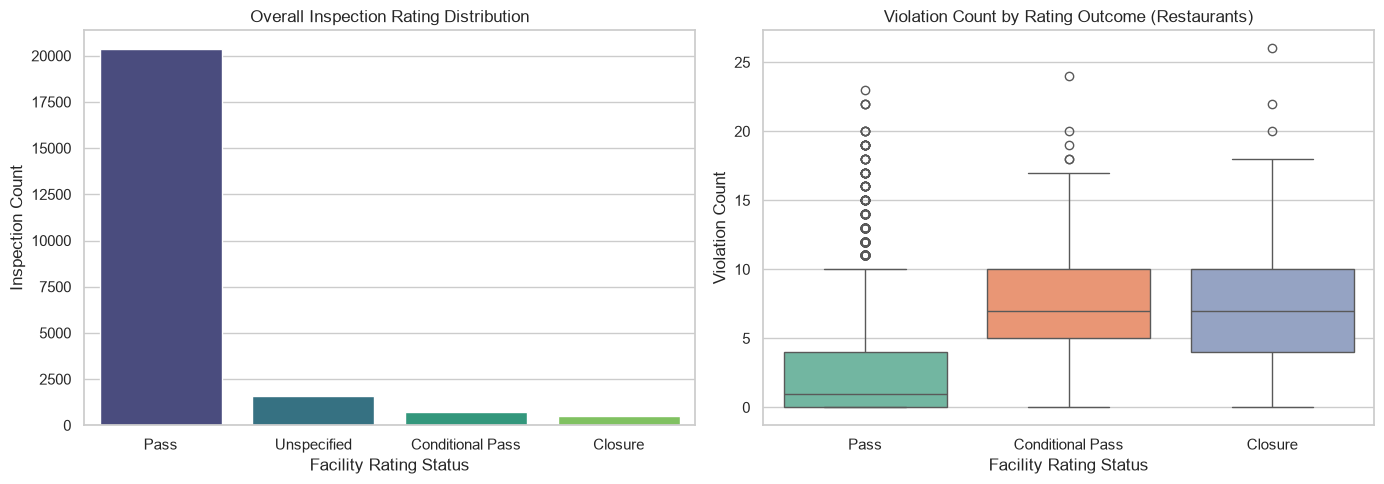

In [4]:
restaurants = df.loc[df['is_restaurant']].copy()
restaurants['size_tier'] = restaurants['permit_type'].str.extract(r'^(H2[456]R?)', expand=False).str[:3]
tier_labels = {
    'H24': 'Small (<1,000 sqft)',
    'H25': 'Medium (1,000-2,000 sqft)',
    'H26': 'Large (>2,000 sqft)',
}
restaurants['size_label'] = restaurants['size_tier'].map(tier_labels)

rated_rest = restaurants.loc[restaurants['facility_rating_status'] != 'Unspecified']
outcome_summary = (
    rated_rest.groupby(['size_label', 'facility_rating_status'])
    .size()
    .unstack(fill_value=0)
)
outcome_summary['Non-Pass Rate (%)'] = (
    (outcome_summary.get('Conditional Pass', 0) + outcome_summary.get('Closure', 0))
    / outcome_summary.sum(axis=1) * 100
).round(2)
display(outcome_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

status_counts = df['facility_rating_status'].value_counts()
sns.barplot(
    x=status_counts.index,
    y=status_counts.values,
    hue=status_counts.index,
    palette='viridis',
    legend=False,
    ax=axes[0],
)
axes[0].set_title('Overall Inspection Rating Distribution')
axes[0].set_xlabel('Facility Rating Status')
axes[0].set_ylabel('Inspection Count')

sns.boxplot(
    data=rated_rest,
    x='facility_rating_status',
    y='violation_count',
    order=['Pass', 'Conditional Pass', 'Closure'],
    hue='facility_rating_status',
    palette='Set2',
    legend=False,
    ax=axes[1],
)
axes[1].set_title('Violation Count by Rating Outcome (Restaurants)')
axes[1].set_xlabel('Facility Rating Status')
axes[1].set_ylabel('Violation Count')

plt.tight_layout()
plt.savefig('visualizations/outcome_and_violations.png', dpi=150, bbox_inches='tight')
plt.show()

### 3.2 Inspection Types & Monthly Non-Pass Trend
Examine which inspection types (`Routine`, `Complaint (I)`, `Foodborne Illness`, `Reinspection`) drive the highest violation counts and track monthly inspection volume alongside non-pass rates.

,inspections,avg_violations,avg_duration_min,non_pass_pct
inspection_type,,,,
Routine,9223,3.01,57.15,8.11
Unspecified,6500,2.56,59.14,3.26
Reinspection,3063,1.87,40.58,5.62
New Ownership (I),1270,0.10,56.57,0.24
Site Visit,832,0.19,33.30,0.72
New Ownership (R),711,0.10,55.33,0.70
Complaint (I),694,0.21,47.26,2.59
Structural,335,0.24,25.07,0.00


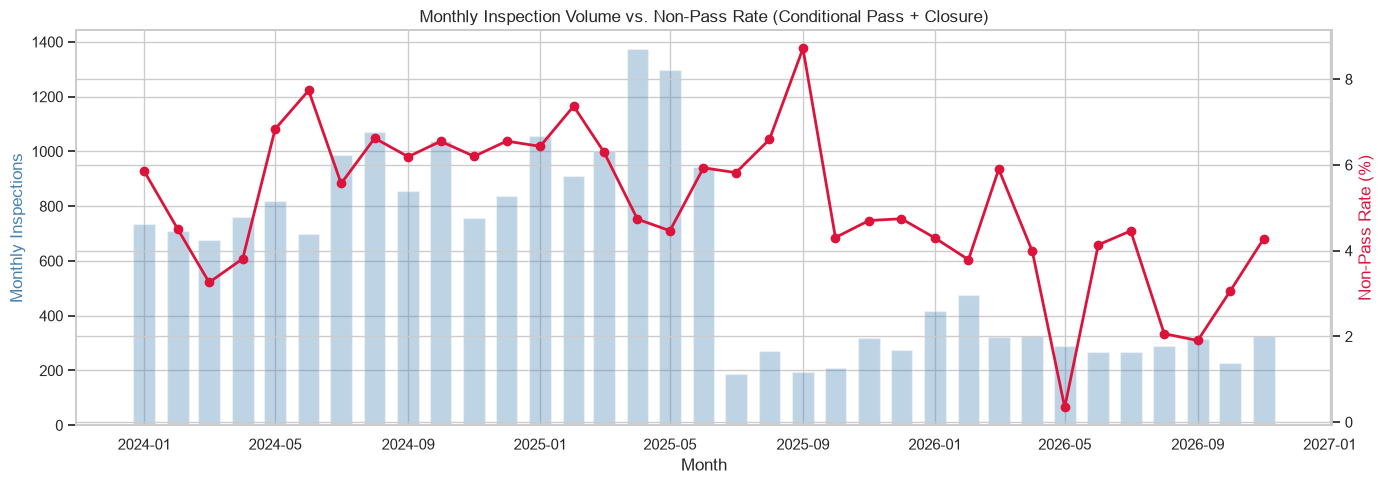

In [5]:
top_types = df['inspection_type'].value_counts().head(8).index
type_stats = (
    df.loc[df['inspection_type'].isin(top_types)]
    .groupby('inspection_type')
    .agg(
        inspections=('permit_number', 'size'),
        avg_violations=('violation_count', 'mean'),
        avg_duration_min=('total_time', 'mean'),
        non_pass_pct=('is_non_pass', lambda s: s.mean() * 100),
    )
    .round(2)
    .sort_values('inspections', ascending=False)
)
display(type_stats)

monthly = (
    df.loc[df['facility_rating_status'] != 'Unspecified']
    .groupby('year_month')
    .agg(
        inspections=('permit_number', 'size'),
        non_pass_rate=('is_non_pass', lambda s: s.mean() * 100),
    )
    .reset_index()
)

fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.bar(monthly['year_month'], monthly['inspections'], width=20, alpha=0.35, color='steelblue', label='Total Rated Inspections')
ax1.set_ylabel('Monthly Inspections', color='steelblue')
ax1.set_xlabel('Month')

ax2 = ax1.twinx()
ax2.plot(monthly['year_month'], monthly['non_pass_rate'], color='crimson', marker='o', linewidth=2, label='Non-Pass Rate (%)')
ax2.set_ylabel('Non-Pass Rate (%)', color='crimson')
ax1.set_title('Monthly Inspection Volume vs. Non-Pass Rate (Conditional Pass + Closure)')
plt.tight_layout()
plt.savefig('visualizations/monthly_compliance_trend.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Neighborhood & Geospatial Risk Analysis

Identify San Francisco neighborhoods with elevated violation averages and non-pass rates (filtering to neighborhoods with at least 200 rated inspections for statistical stability), and plot validated coordinates across the city.

,rated_inspections,avg_violations,non_pass_rate_pct,closures
analysis_neighborhood,,,,
Japantown,250,2.83,12.40,7
Bernal Heights,333,3.09,9.91,15
Lakeshore,252,3.16,8.73,13
Mission,2506,3.30,8.18,72
Chinatown,1404,2.72,7.98,50
Castro/Upper Market,435,1.75,7.59,12
Marina,568,1.68,7.57,7
North Beach,1062,3.18,7.53,37
Noe Valley,293,2.84,7.17,10


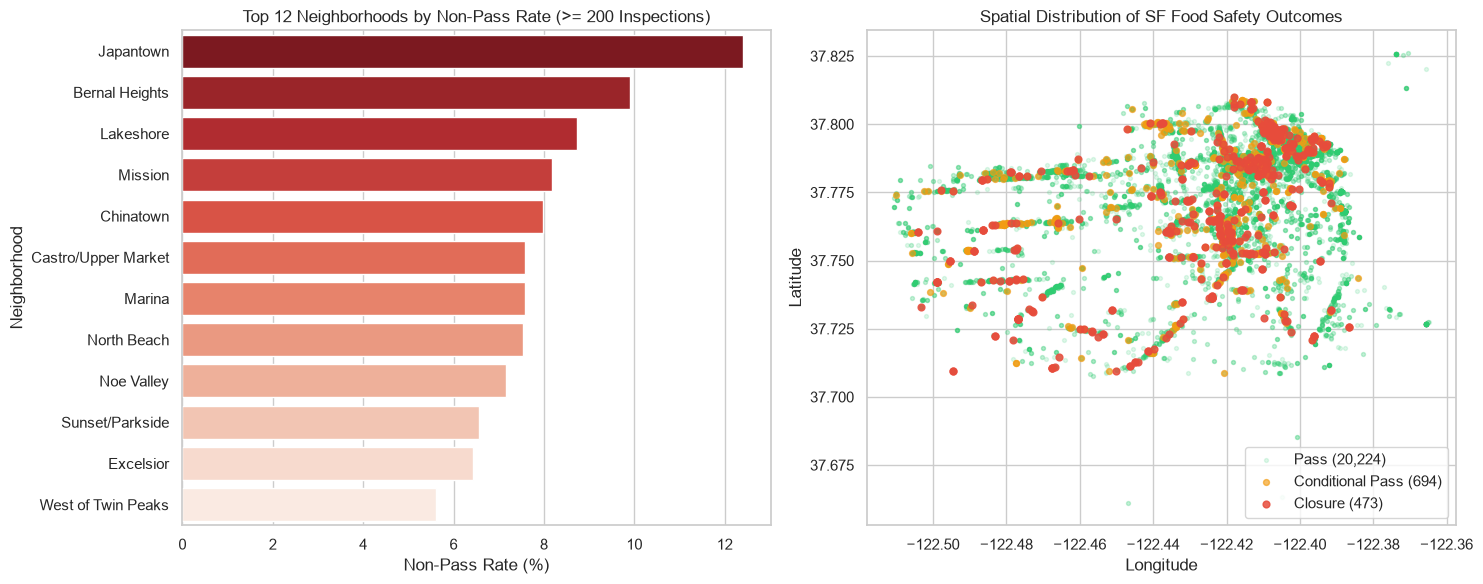

In [6]:
rated_df = df.loc[df['facility_rating_status'] != 'Unspecified']
neigh_stats = (
    rated_df.groupby('analysis_neighborhood')
    .agg(
        rated_inspections=('permit_number', 'size'),
        avg_violations=('violation_count', 'mean'),
        non_pass_rate_pct=('is_non_pass', lambda s: s.mean() * 100),
        closures=('facility_rating_status', lambda s: (s == 'Closure').sum()),
    )
    .query('rated_inspections >= 200')
    .sort_values('non_pass_rate_pct', ascending=False)
    .round(2)
)
display(neigh_stats.head(15))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

top12 = neigh_stats.head(12).reset_index()
sns.barplot(
    data=top12,
    y='analysis_neighborhood',
    x='non_pass_rate_pct',
    hue='analysis_neighborhood',
    palette='Reds_r',
    legend=False,
    ax=axes[0],
)
axes[0].set_title('Top 12 Neighborhoods by Non-Pass Rate (>= 200 Inspections)')
axes[0].set_xlabel('Non-Pass Rate (%)')
axes[0].set_ylabel('Neighborhood')

geo = rated_df.loc[rated_df['valid_sf_coords']].copy()
for status, color, alpha, size in [
    ('Pass', '#2ecc71', 0.15, 8),
    ('Conditional Pass', '#f39c12', 0.65, 18),
    ('Closure', '#e74c3c', 0.85, 24),
]:
    subset = geo.loc[geo['facility_rating_status'] == status]
    axes[1].scatter(subset['longitude'], subset['latitude'], c=color, alpha=alpha, s=size, label=f"{status} ({len(subset):,})")

axes[1].set_title('Spatial Distribution of SF Food Safety Outcomes')
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.savefig('visualizations/neighborhood_risk_and_map.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Violation Code Mining & Reinspection Turnaround

### 5.1 Most Frequently Cited California Retail Food Code Sections
Parse CalCode section numbers (`11xxxx`) from the free-text `violation_codes` field to uncover the leading drivers of food safety citations.

,calcode_section,citations
0,114067,6613
1,114143,5965
2,114259,5965
3,113984,5068
4,113953,5035
5,114163,5016
6,114101,4637
7,114125,4637
8,114259.1,4082
9,114259.4,4082


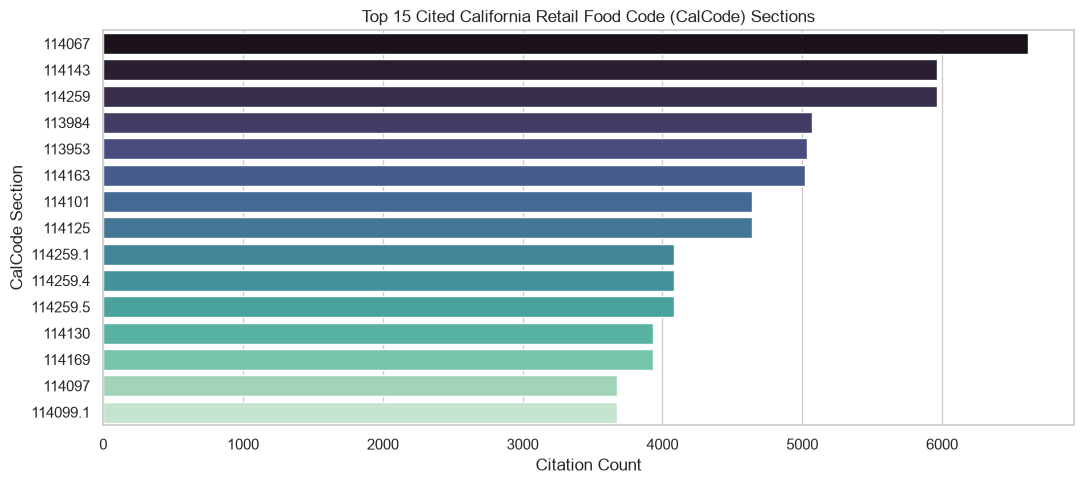

In [7]:
code_series = df['violation_codes'].dropna().astype(str)
all_codes = code_series.str.findall(r'\b(11\d{4}(?:\.\d+)?)\b').explode().dropna()

top_codes = all_codes.value_counts().head(15).rename_axis('calcode_section').reset_index(name='citations')
display(top_codes)

plt.figure(figsize=(11, 5))
sns.barplot(
    data=top_codes,
    y='calcode_section',
    x='citations',
    hue='calcode_section',
    palette='mako',
    legend=False,
)
plt.title('Top 15 Cited California Retail Food Code (CalCode) Sections')
plt.xlabel('Citation Count')
plt.ylabel('CalCode Section')
plt.tight_layout()
plt.savefig('visualizations/top_calcode_citations.png', dpi=150, bbox_inches='tight')
plt.show()

### 5.2 Repeat Non-Pass Establishments & Reinspection Turnaround
Aggregate at the permit level (`permit_number`, `dba`) to identify establishments with repeated `Conditional Pass` or `Closure` outcomes, and measure the day gap between an initial non-pass inspection and the subsequent `Reinspection`.

In [8]:
repeat_offenders = (
    rated_df.loc[rated_df['is_non_pass']]
    .groupby(['permit_number', 'dba', 'analysis_neighborhood'])
    .agg(
        non_pass_events=('facility_rating_status', 'size'),
        closures=('facility_rating_status', lambda s: (s == 'Closure').sum()),
        max_violations=('violation_count', 'max'),
        last_non_pass=('inspection_date', 'max'),
    )
    .sort_values(['non_pass_events', 'closures', 'max_violations'], ascending=False)
    .head(15)
)
display(repeat_offenders)

# Measure days from a non-pass inspection to the next Reinspection for the same permit
sorted_insp = df.sort_values(['permit_number', 'inspection_date']).copy()
non_pass_dates = sorted_insp.loc[sorted_insp['is_non_pass'], ['permit_number', 'inspection_date']].rename(
    columns={'inspection_date': 'non_pass_date'}
)
reinsp_dates = sorted_insp.loc[sorted_insp['inspection_type'] == 'Reinspection', ['permit_number', 'inspection_date']].rename(
    columns={'inspection_date': 'reinspection_date'}
)

paired = non_pass_dates.merge(reinsp_dates, on='permit_number', how='inner')
paired['days_to_reinspection'] = (paired['reinspection_date'] - paired['non_pass_date']).dt.days
valid_gaps = paired.loc[paired['days_to_reinspection'].between(0, 90)]
nearest_reinsp = valid_gaps.sort_values('days_to_reinspection').groupby(['permit_number', 'non_pass_date']).first()

print(f"Matched non-pass -> reinspection pairs (0-90 days): {len(nearest_reinsp):,}")
print(nearest_reinsp['days_to_reinspection'].describe().round(2))

,,,non_pass_events,closures,max_violations,last_non_pass
permit_number,dba,analysis_neighborhood,,,,
103413,YARSA NEPALESE CUISINE,North Beach,7,5,9,2025-06-25
115579,TCM FORTUNE,Outer Richmond,6,3,12,2026-07-14
99421,HONG KONG LOUNGE,Outer Richmond,6,2,11,2026-04-28
31974,GOLDEN FLOWER VIETNAMESE RESTA,Chinatown,5,5,15,2025-06-04
108781,PICA PICA,Mission,5,4,12,2025-03-10
FYF120431,DOSA CORNER INDIAN CUISINE,Mission,5,3,13,2025-03-28
106260,CITY LUNCH RESTAURANT,Bayview Hunters Point,5,2,14,2026-02-03
86296,SAAP VER,Mission Bay,5,2,8,2025-05-16
06733668,THE PORT OF PERI PERI,Mission Bay,5,1,16,2025-04-18


Matched non-pass -> reinspection pairs (0-90 days): 859
count    859.00
mean       6.80
std       10.05
min        0.00
25%        1.00
50%        3.00
75%        8.00
max       88.00
Name: days_to_reinspection, dtype: float64


## 6. Predictive Non-Pass Risk Modeling (`RandomForestClassifier`)

To help prioritize proactive health inspections, we train a binary classifier predicting `is_non_pass` (`Conditional Pass` or `Closure`) strictly from **pre-inspection information** (preventing target leakage by excluding same-inspection `violation_count`, `violation_codes`, and `total_time`):
- **Historical Permit Features (strictly prior via `.shift(1)` within `permit_number`):** `prior_inspections`, `prior_non_pass_count`, `prior_avg_violations`, and `days_since_last_inspection`.
- **Facility & Scheduling Context:** `permit_type`, `inspection_type`, `inspection_frequency_type`, `analysis_neighborhood`, `supervisor_district`, `month`, `day_of_week`, and validated SF coordinates.
- **Chronological 80/20 Split:** Train on the earliest 80% of rated inspections by `inspection_date` and evaluate on the latest 20%.

In [9]:
# Build leak-free modeling table on rated inspections sorted chronologically per permit
model_df = rated_df.sort_values(['permit_number', 'inspection_date']).copy()
permit_grp = model_df.groupby('permit_number', group_keys=False)

model_df['prior_inspections'] = permit_grp.cumcount()
model_df['prior_non_pass_count'] = (
    permit_grp['is_non_pass'].cumsum().shift(1).where(model_df['prior_inspections'] > 0, 0)
).astype(int)
model_df['prior_avg_violations'] = (
    permit_grp['violation_count']
    .expanding()
    .mean()
    .reset_index(level=0, drop=True)
    .shift(1)
    .where(model_df['prior_inspections'] > 0, 0.0)
)
model_df['days_since_last_inspection'] = permit_grp['inspection_date'].diff().dt.days.fillna(-1)

model_df['month'] = model_df['inspection_date'].dt.month
model_df['day_of_week'] = model_df['inspection_date'].dt.day_of_week
model_df['lat_clean'] = model_df['latitude'].where(model_df['valid_sf_coords'], np.nan)
model_df['lon_clean'] = model_df['longitude'].where(model_df['valid_sf_coords'], np.nan)
model_df['supervisor_district'] = model_df['supervisor_district'].astype(object).fillna('Unknown').astype(str)
model_df['inspection_frequency_type'] = model_df['inspection_frequency_type'].fillna('Unspecified').astype(str)
model_df['permit_type'] = model_df['permit_type'].fillna('Unspecified').astype(str)

NUMERIC_FEATURES = [
    'prior_inspections',
    'prior_non_pass_count',
    'prior_avg_violations',
    'days_since_last_inspection',
    'month',
    'day_of_week',
    'lat_clean',
    'lon_clean',
]
CATEGORICAL_FEATURES = [
    'permit_type',
    'inspection_type',
    'inspection_frequency_type',
    'analysis_neighborhood',
    'supervisor_district',
]

# Chronological 80 / 20 split by inspection_date
model_df = model_df.sort_values('inspection_date').reset_index(drop=True)
split_idx = int(len(model_df) * 0.80)
train_df = model_df.iloc[:split_idx].copy()
test_df = model_df.iloc[split_idx:].copy()

X_train = train_df[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
y_train = train_df['is_non_pass'].astype(int)
X_test = test_df[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
y_test = test_df['is_non_pass'].astype(int)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), NUMERIC_FEATURES),
        (
            'cat',
            Pipeline([
                ('imputer', SimpleImputer(strategy='most_frequent')),
                ('ohe', OneHotEncoder(handle_unknown='ignore')),
            ]),
            CATEGORICAL_FEATURES,
        ),
    ]
)

clf_pipeline = Pipeline([
    ('prep', preprocessor),
    (
        'clf',
        RandomForestClassifier(
            n_estimators=200,
            max_depth=14,
            class_weight='balanced',
            random_state=42,
            n_jobs=-1,
        ),
    ),
])

clf_pipeline.fit(X_train, y_train)
y_prob = clf_pipeline.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

roc_auc = roc_auc_score(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)
print(f"Chronological Split -> Train: {len(train_df):,} ({train_df['inspection_date'].min().date()} to {train_df['inspection_date'].max().date()})")
print(f"                       Test:  {len(test_df):,} ({test_df['inspection_date'].min().date()} to {test_df['inspection_date'].max().date()})")
print(f"Test ROC-AUC: {roc_auc:.4f} | Test PR-AUC: {pr_auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Pass', 'Non-Pass']))

MODEL_PATH = 'model/food_safety_random_forest_model.pkl'
joblib.dump(
    {
        'model': clf_pipeline,
        'numeric_features': NUMERIC_FEATURES,
        'categorical_features': CATEGORICAL_FEATURES,
        'threshold': 0.5,
    },
    MODEL_PATH,
)
print(f"Saved trained model artifact -> {MODEL_PATH}")

Chronological Split -> Train: 17,216 (2024-01-02 to 2025-10-02)
                       Test:  4,304 (2025-10-03 to 2026-11-20)
Test ROC-AUC: 0.6300 | Test PR-AUC: 0.0811

Classification Report:
              precision    recall  f1-score   support

        Pass       0.97      0.98      0.97      4144
    Non-Pass       0.16      0.11      0.13       160

    accuracy                           0.95      4304
   macro avg       0.56      0.55      0.55      4304
weighted avg       0.94      0.95      0.94      4304

Saved trained model artifact -> model/food_safety_random_forest_model.pkl


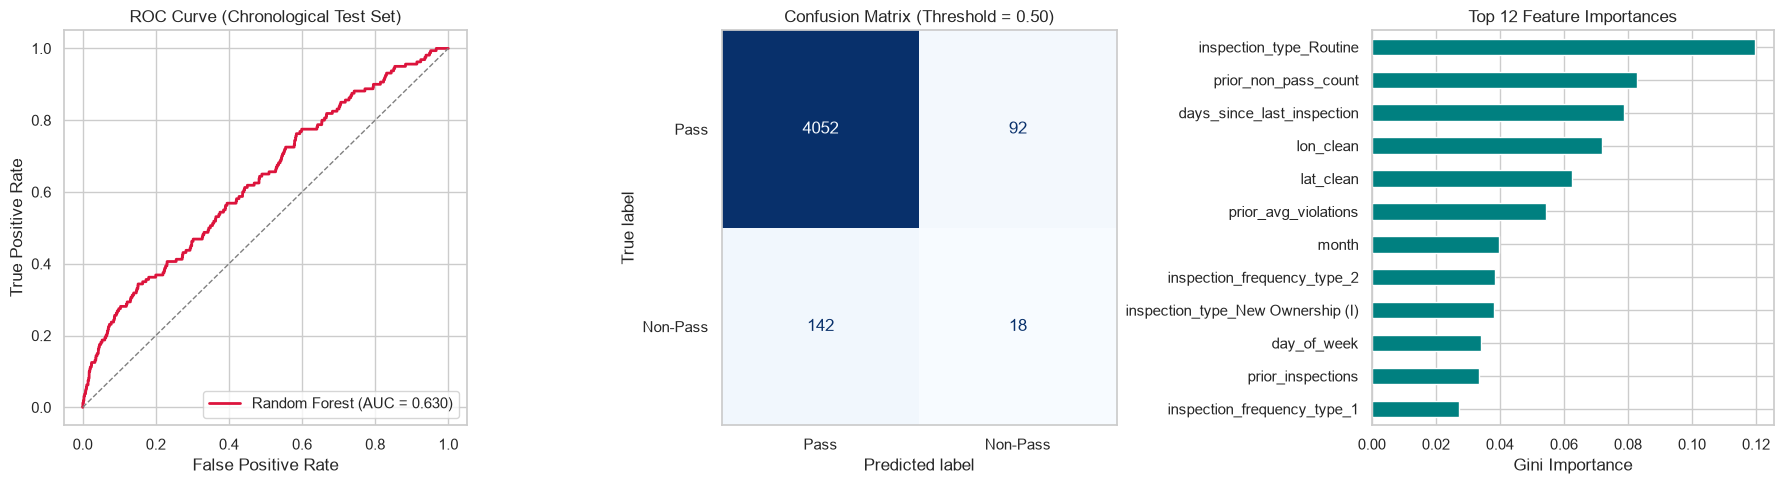

In [10]:
# Model evaluation charts: ROC curve, confusion matrix, and top feature importances
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[0].plot(fpr, tpr, color='crimson', lw=2, label=f'Random Forest (AUC = {roc_auc:.3f})')
axes[0].plot([0, 1], [0, 1], color='gray', linestyle='dashed', lw=1)
axes[0].set_title('ROC Curve (Chronological Test Set)')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right')

# 2. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['Pass', 'Non-Pass']).plot(ax=axes[1], cmap='Blues', colorbar=False)
axes[1].grid(False)
axes[1].set_title('Confusion Matrix (Threshold = 0.50)')

# 3. Top 12 Feature Importances
ohe_names = clf_pipeline.named_steps['prep'].named_transformers_['cat'].named_steps['ohe'].get_feature_names_out(CATEGORICAL_FEATURES)
all_feature_names = NUMERIC_FEATURES + list(ohe_names)
importances = pd.Series(clf_pipeline.named_steps['clf'].feature_importances_, index=all_feature_names)
top_imp = importances.sort_values(ascending=False).head(12)
top_imp.sort_values().plot(kind='barh', ax=axes[2], color='teal')
axes[2].set_title('Top 12 Feature Importances')
axes[2].set_xlabel('Gini Importance')

plt.tight_layout()
plt.savefig('visualizations/model_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Interactive Geospatial Risk Map (`folium`)

Visualize recent San Francisco facility compliance outcomes alongside predicted non-pass probabilities using the exported `model/food_safety_random_forest_model.pkl` artifact, saving the interactive map to `visualizations/sf_food_safety_map.html`.

In [11]:
loaded_artifact = joblib.load('model/food_safety_random_forest_model.pkl')
risk_model = loaded_artifact['model']
req_cols = loaded_artifact['numeric_features'] + loaded_artifact['categorical_features']

# Score latest valid-coordinate inspection per permit
latest_permits = (
    model_df.loc[model_df['valid_sf_coords']]
    .sort_values('inspection_date')
    .groupby('permit_number', as_index=False)
    .last()
)
latest_permits['predicted_non_pass_prob'] = risk_model.predict_proba(latest_permits[req_cols])[:, 1]

# Include all Closure & Conditional Pass facilities plus up to 400 recent Pass facilities for responsive rendering
non_pass_pts = latest_permits.loc[latest_permits['is_non_pass']]
pass_pts = latest_permits.loc[~latest_permits['is_non_pass']].tail(400)
map_pts = pd.concat([pass_pts, non_pass_pts], ignore_index=True)

sf_map = folium.Map(location=[37.7749, -122.4194], zoom_start=12)
status_colors = {'Pass': '#2ecc71', 'Conditional Pass': '#f39c12', 'Closure': '#e74c3c'}

for _, row in map_pts.iterrows():
    color = status_colors.get(row['facility_rating_status'], '#3498db')
    folium.CircleMarker(
        location=[row['lat_clean'], row['lon_clean']],
        radius=6 if row['is_non_pass'] else 4,
        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=0.8 if row['is_non_pass'] else 0.45,
        popup=(
            f"<b>{row['dba']}</b><br>"
            f"Neighborhood: {row['analysis_neighborhood']}<br>"
            f"Latest Outcome: {row['facility_rating_status']}<br>"
            f"Predicted Non-Pass Risk: {row['predicted_non_pass_prob'] * 100:.1f}%"
        ),
    ).add_to(sf_map)

MAP_PATH = 'visualizations/sf_food_safety_map.html'
sf_map.save(MAP_PATH)
print(f"Saved interactive SF Food Safety map ({len(map_pts):,} facilities) -> {MAP_PATH}")
display(IFrame(src=MAP_PATH, width='100%', height='480px'))

Saved interactive SF Food Safety map (557 facilities) -> visualizations/sf_food_safety_map.html


## 8. Summary of Key Findings

- **Single Modern Dataset:** Consolidating onto DataSF `tvy3-wexg` (`23,243` inspections) eliminates fragmented multi-table joins while providing up-to-date inspection logs, durations, neighborhoods, and CalCode citations.
- **Data Quality Matters:** Auditing revealed a `2031-05-16` future-date outlier, negative `total_time` durations down to `-1320` minutes, non-food permits (`H31` tobacco retail) mixed into health inspection logs, and out-of-bounds coordinates outside San Francisco.
- **Compliance & Risk Signals:** Most rated inspections result in `Pass` (`20,350` vs. `694` `Conditional Pass` and `476` `Closure`), while higher `violation_count`, neighborhood clustering, and repeat `Conditional Pass`/`Closure` events highlight clear operational risk segments.
- **Predictive Prioritization & Visualizations:** A leak-free `RandomForestClassifier` trained on prior permit history and scheduling/location metadata is exported to `model/food_safety_random_forest_model.pkl`, paired with exported charts and `visualizations/sf_food_safety_map.html`.